# PathSnap — Model Training, Bayesian Optimization & Evaluation
**Team 15 · Section 5-D**

This notebook starts from the model-ready CSV files generated by the completed EDA and candidate-generation notebook. It does not repeat data extraction, EDA, candidate generation, or feature engineering.

**Outputs:** trained model files, configuration, validation and student-test metrics, candidate-level and observation-level metrics, confusion matrices, comparison charts, feature importance, experiment log, and report-ready CSVs/plots.

> Run top-to-bottom in Google Colab. The Bayesian search is intentionally compact (8 trials on a reproducible stratified sample) to finish quickly. The search is for Random Forest, selected as the leading candidate from the initial experiments. Validation is used for model selection; student-test results are reported only after selection.

## 1. Setup and load the completed EDA outputs

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install optuna joblib seaborn

from pathlib import Path
import os, json, time, warnings, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")

PROJECT_DIR = Path('/content/drive/MyDrive/PathSnap')
OUTPUT_DIR = PROJECT_DIR / 'outputs'
MODEL_DIR = PROJECT_DIR / 'models'
RESULT_DIR = PROJECT_DIR / 'model_training_results'
for p in [MODEL_DIR, RESULT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = OUTPUT_DIR / 'pathsnap_train_model_ready.csv'
TEST_PATH = OUTPUT_DIR / 'pathsnap_student_test_model_ready.csv'
assert TRAIN_PATH.exists(), f'Missing {TRAIN_PATH}. Run the EDA/candidate pipeline first.'
assert TEST_PATH.exists(), f'Missing {TEST_PATH}. Run the EDA/candidate pipeline first.'

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
print('Python:', sys.version)
print('Platform:', platform.platform())
print('Train:', train_df.shape, '| Student-test:', test_df.shape)
print('Columns:', train_df.columns.tolist())

Mounted at /content/drive
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Train: (1333521, 16) | Student-test: (166448, 16)
Columns: ['trip_id', 'partition', 'obs_index', 'timestamp', 'arc_id', 'dist_to_segment', 'projection_ratio', 'heading_diff', 'segment_length', 'dist_to_start', 'dist_to_end', 'gps_speed', 'candidate_rank', 'aligned_route_arc_id', 'route_alignment_distance', 'label']


## 2. Define features and create a trip-wise validation split
The split is grouped by trip ID to prevent observations from the same trip appearing in both training and validation.

In [2]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix, classification_report,
    average_precision_score, roc_auc_score)

FEATURES = [
    'dist_to_segment', 'projection_ratio', 'heading_diff',
    'segment_length', 'dist_to_start', 'dist_to_end',
    'gps_speed', 'candidate_rank'
]
TARGET = 'label'
required = FEATURES + [TARGET, 'trip_id', 'obs_index']
missing = [c for c in required if c not in train_df.columns or c not in test_df.columns]
assert not missing, f'Missing required columns: {missing}'

# Numeric conversion; imputation is fitted on training data only.
for df in [train_df, test_df]:
    for col in FEATURES + [TARGET, 'trip_id', 'obs_index']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

train_df = train_df.dropna(subset=[TARGET, 'trip_id', 'obs_index']).copy()
test_df = test_df.dropna(subset=[TARGET, 'trip_id', 'obs_index']).copy()
train_df[TARGET] = train_df[TARGET].astype(int)
test_df[TARGET] = test_df[TARGET].astype(int)

X_all = train_df[FEATURES].replace([np.inf, -np.inf], np.nan)
y_all = train_df[TARGET]
groups = train_df['trip_id']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr_idx, va_idx = next(splitter.split(X_all, y_all, groups=groups))
X_train, X_val = X_all.iloc[tr_idx], X_all.iloc[va_idx]
y_train, y_val = y_all.iloc[tr_idx], y_all.iloc[va_idx]
train_meta = train_df.iloc[tr_idx][['trip_id','obs_index']].copy()
val_meta = train_df.iloc[va_idx][['trip_id','obs_index']].copy()
X_student = test_df[FEATURES].replace([np.inf, -np.inf], np.nan)
y_student = test_df[TARGET]
student_meta = test_df[['trip_id','obs_index']].copy()

print('Train rows:', len(X_train), 'Validation rows:', len(X_val))
print('Train trips:', train_meta.trip_id.nunique(), 'Validation trips:', val_meta.trip_id.nunique())
print('Trip overlap:', len(set(train_meta.trip_id) & set(val_meta.trip_id)))
print('Train positive rate:', round(y_train.mean(), 4))
print('Validation positive rate:', round(y_val.mean(), 4))
print('Student-test positive rate:', round(y_student.mean(), 4))

Train rows: 1068205 Validation rows: 265316
Train trips: 64 Validation trips: 16
Trip overlap: 0
Train positive rate: 0.0338
Validation positive rate: 0.035
Student-test positive rate: 0.0338


## 3. Train the five experimented model families
The configurations below preserve the initial experiments. KNN is trained on a reproducible 100,000-row subset for practical runtime; all models are evaluated on the same full validation set.

In [3]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {}
fit_times = {}

def fit_and_time(name, model, Xfit, yfit):
    t0 = time.time()
    model.fit(Xfit, yfit)
    fit_times[name] = time.time() - t0
    models[name] = model
    print(f'{name}: fitted in {fit_times[name]:.1f}s')
    return model

models['Random Forest'] = RandomForestClassifier(
    n_estimators=100, max_depth=15, min_samples_split=10,
    min_samples_leaf=5, max_features='sqrt',
    class_weight='balanced', n_jobs=-1, random_state=42
)
fit_and_time('Random Forest', models['Random Forest'], X_train, y_train)

models['Logistic Regression'] = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced', max_iter=300, solver='lbfgs', random_state=42
    ))
])
fit_and_time('Logistic Regression', models['Logistic Regression'], X_train, y_train)

models['Decision Tree'] = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(
        max_depth=15, min_samples_split=10, min_samples_leaf=5,
        class_weight='balanced', random_state=42
    ))
])
fit_and_time('Decision Tree', models['Decision Tree'], X_train, y_train)

models['HistGradientBoosting'] = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=31, learning_rate=0.1,
        l2_regularization=1.0, class_weight='balanced', random_state=42
    ))
])
fit_and_time('HistGradientBoosting', models['HistGradientBoosting'], X_train, y_train)

knn_n = min(100000, len(X_train))
knn_idx = X_train.sample(n=knn_n, random_state=42).index
models['KNN'] = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1))
])
fit_and_time('KNN', models['KNN'], X_train.loc[knn_idx], y_train.loc[knn_idx])

Random Forest: fitted in 273.8s
Logistic Regression: fitted in 4.5s
Decision Tree: fitted in 19.0s
HistGradientBoosting: fitted in 13.9s
KNN: fitted in 0.3s


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('knn',
                 KNeighborsClassifier(n_jobs=-1, n_neighbors=7,
                                      weights='distance'))])

## 4. Common evaluation functions and full validation comparison
Candidate-level metrics assess each GPS-observation/road-candidate row. Observation-level Top-1 metrics choose the highest-scoring candidate for each observation and compare it with the supplied candidate label. These are not full-trip route continuity metrics.

In [4]:
def candidate_metrics(y_true, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        'Candidate Accuracy': accuracy_score(y_true, pred),
        'Candidate Precision': precision_score(y_true, pred, zero_division=0),
        'Candidate Recall': recall_score(y_true, pred, zero_division=0),
        'Candidate F1': f1_score(y_true, pred, zero_division=0),
        'Macro F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'Log Loss': log_loss(y_true, np.clip(prob, 1e-7, 1-1e-7), labels=[0,1]),
        'ROC AUC': roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        'Average Precision': average_precision_score(y_true, prob)
    }

def observation_top1(df_meta, y_true, prob):
    z = df_meta[['trip_id','obs_index']].copy().reset_index(drop=True)
    z['y'] = np.asarray(y_true)
    z['prob'] = np.asarray(prob)
    z = z.sort_values(['trip_id','obs_index','prob'], ascending=[True,True,False])
    top = z.groupby(['trip_id','obs_index'], as_index=False).first()
    # An observation is correct when the top-ranked candidate is the labelled true arc.
    # Each observation contributes exactly one selected candidate. It is correct
    # only when that selected candidate carries the positive (reference-arc) label.
    top1_pred = np.ones(len(top), dtype=int)
    return {
        'Observation Top-1 Accuracy': float((top['y'].to_numpy() == 1).mean()),
        'Observation Macro F1': f1_score(top['y'], top1_pred,
                                        average='macro', zero_division=0),
        'Observations Evaluated': len(top)
    }

validation_probs = {}
validation_preds = {}
rows = []
inference_times = {}

for name, model in models.items():
    t0 = time.time()
    prob = model.predict_proba(X_val)[:,1]
    inference_times[name] = time.time() - t0
    validation_probs[name] = prob
    validation_preds[name] = (prob >= 0.5).astype(int)
    row = {'Model': name, **candidate_metrics(y_val, prob)}
    row.update(observation_top1(val_meta, y_val, prob))
    row['Training Time (s)'] = fit_times[name]
    row['Validation Inference Time (s)'] = inference_times[name]
    rows.append(row)

validation_results = pd.DataFrame(rows).sort_values('Macro F1', ascending=False)
display(validation_results.round(4))
validation_results.to_csv(RESULT_DIR/'validation_model_comparison.csv', index=False)

,Model,Candidate Accuracy,Candidate Precision,Candidate Recall,Candidate F1,Macro F1,Log Loss,ROC AUC,Average Precision,Observation Top-1 Accuracy,Observation Macro F1,Observations Evaluated,Training Time (s),Validation Inference Time (s)
0,Random Forest,0.9798,0.6460,0.9328,0.7633,0.8764,0.0653,0.9915,0.8844,0.8296,0.4534,9600,273.8081,1.7935
4,KNN,0.9829,0.7591,0.7493,0.7542,0.8727,0.0898,0.9591,0.7544,0.7769,0.4372,9600,0.3216,11.1844
2,Decision Tree,0.9710,0.5499,0.9400,0.6939,0.8393,0.1090,0.9649,0.8494,0.8233,0.4516,9600,19.0040,0.0409
3,HistGradientBoosting,0.9661,0.5083,0.9638,0.6656,0.8239,0.0954,0.9917,0.8892,0.8278,0.4529,9600,13.8812,2.0890
1,Logistic Regression,0.9079,0.2721,0.9753,0.4255,0.6877,0.1863,0.9838,0.7360,0.8118,0.4481,9600,4.4730,0.0353


## 5. Confusion matrices and model comparison charts

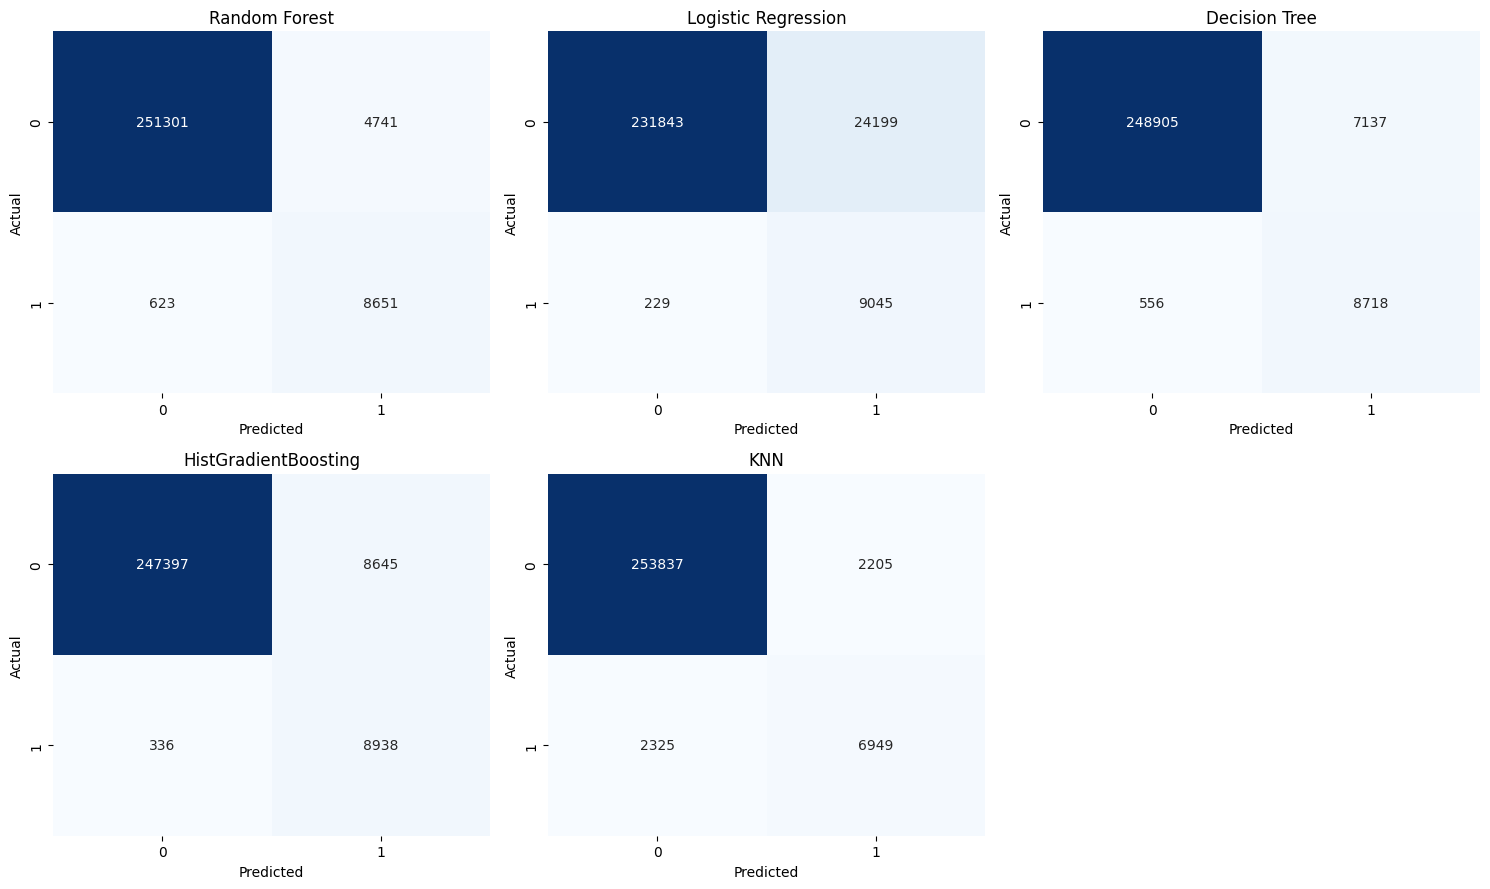

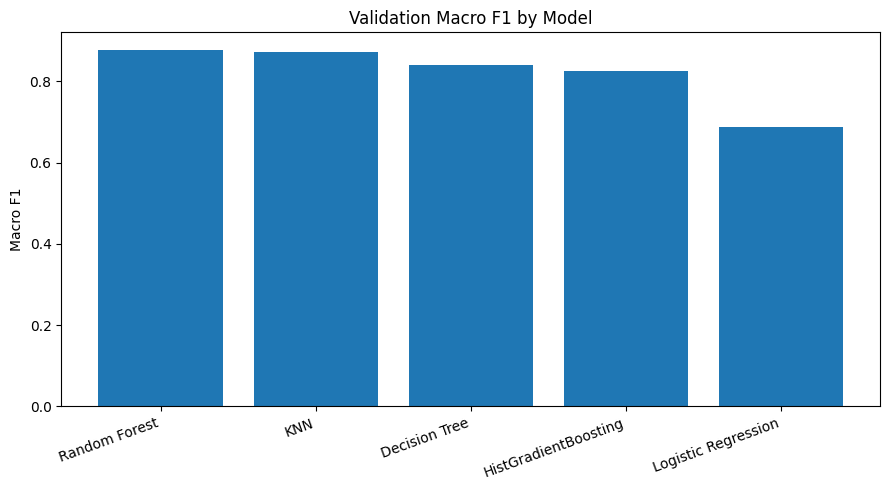

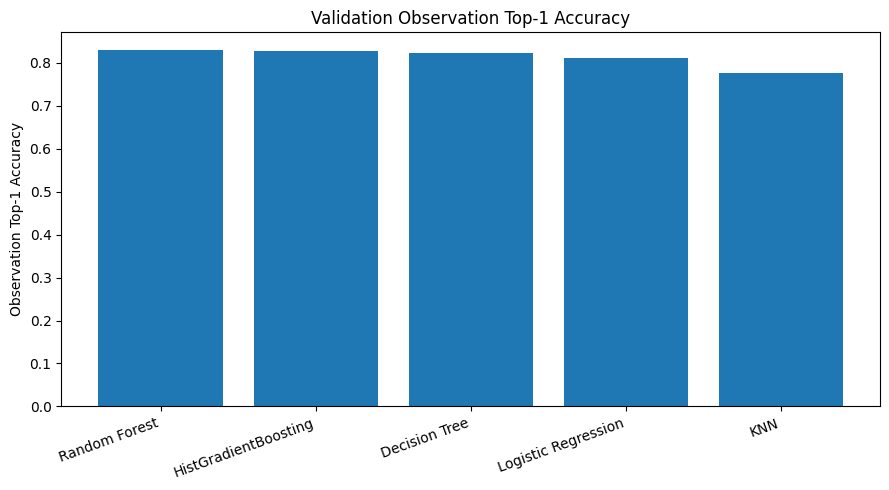

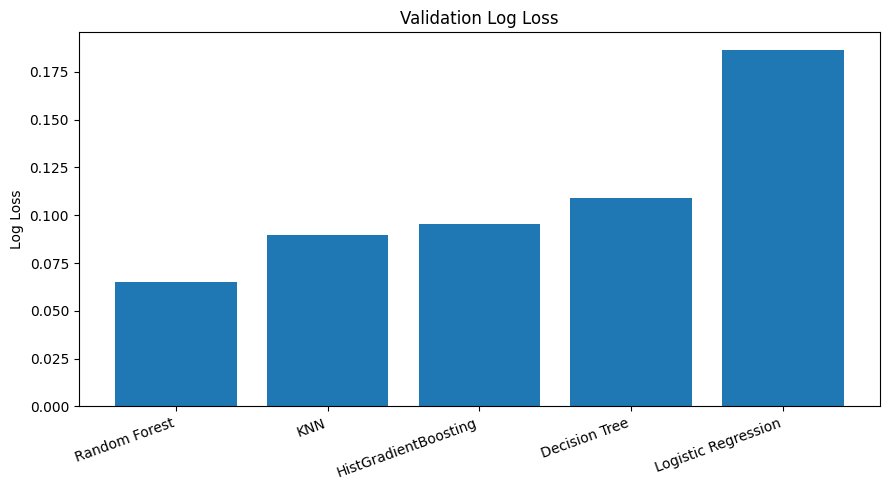

In [5]:
# Per-model confusion matrices (validation, threshold 0.50)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, (name, pred) in zip(axes, validation_preds.items()):
    cm = confusion_matrix(y_val, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
for ax in axes[len(validation_preds):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(RESULT_DIR/'validation_confusion_matrices.png', dpi=180)
plt.show()

for metric, filename, title in [
    ('Macro F1','validation_macro_f1.png','Validation Macro F1 by Model'),
    ('Observation Top-1 Accuracy','validation_observation_top1.png','Validation Observation Top-1 Accuracy'),
    ('Log Loss','validation_log_loss.png','Validation Log Loss')
]:
    plot_df = validation_results.sort_values(metric, ascending=(metric=='Log Loss'))
    plt.figure(figsize=(9,5))
    plt.bar(plot_df['Model'], plot_df[metric])
    plt.xticks(rotation=20, ha='right')
    plt.ylabel(metric); plt.title(title); plt.tight_layout()
    plt.savefig(RESULT_DIR/filename, dpi=180)
    plt.show()

## 6. Random Forest feature importance

,Feature,Importance
7,candidate_rank,0.330909
0,dist_to_segment,0.290572
1,projection_ratio,0.131543
2,heading_diff,0.108847
3,segment_length,0.042429
5,dist_to_end,0.041586
4,dist_to_start,0.035388
6,gps_speed,0.018727


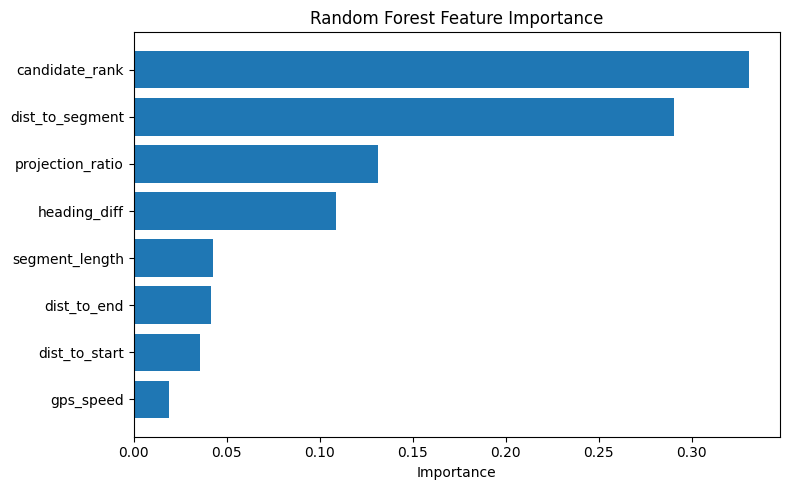

In [6]:
rf_initial = models['Random Forest']
if hasattr(rf_initial, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': FEATURES, 'Importance': rf_initial.feature_importances_
    }).sort_values('Importance', ascending=False)
    display(importance_df)
    plt.figure(figsize=(8,5))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.gca().invert_yaxis()
    plt.xlabel('Importance'); plt.title('Random Forest Feature Importance')
    plt.tight_layout()
    plt.savefig(RESULT_DIR/'random_forest_feature_importance.png', dpi=180)
    plt.show()
    importance_df.to_csv(RESULT_DIR/'random_forest_feature_importance.csv', index=False)

## 7. Bayesian hyperparameter optimization (Optuna TPE)
A compact TPE search is run on a stratified sample of the training and validation rows for runtime. The validation sample is used only for tuning; the final student-test partition remains untouched until Section 9. Search objective: validation Macro F1. Search space and all trial results are saved.

In [7]:
import optuna
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Cap tuning data to keep the search practical on Colab CPU.
TUNE_TRAIN_N = min(160000, len(X_train))
TUNE_VAL_N = min(60000, len(X_val))
X_tune_train, _, y_tune_train, _ = train_test_split(
    X_train, y_train, train_size=TUNE_TRAIN_N,
    stratify=y_train, random_state=42
)
X_tune_val, _, y_tune_val, _ = train_test_split(
    X_val, y_val, train_size=TUNE_VAL_N,
    stratify=y_val, random_state=43
)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 80, 160, step=40),
        'max_depth': trial.suggest_int('max_depth', 10, 22, step=4),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 20, step=5),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 10, step=2),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 0.7]),
        'class_weight': 'balanced',
        'n_jobs': -1,
        'random_state': 42
    }
    clf = RandomForestClassifier(**params)
    clf.fit(X_tune_train, y_tune_train)
    p = clf.predict_proba(X_tune_val)[:,1]
    pred = (p >= 0.5).astype(int)
    return f1_score(y_tune_val, pred, average='macro', zero_division=0)

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler,
                            study_name='PathSnap_RF_TPE_MacroF1')
study.optimize(objective, n_trials=8, show_progress_bar=True)

print('Best Macro F1:', study.best_value)
print('Best parameters:', study.best_params)
trials_df = study.trials_dataframe()
display(trials_df)
trials_df.to_csv(RESULT_DIR/'optuna_rf_trials.csv', index=False)
with open(RESULT_DIR/'optuna_rf_best_config.json','w') as f:
    json.dump({
        'sampler':'Optuna TPESampler',
        'objective':'Validation sample Macro F1 at threshold 0.5',
        'n_trials':len(study.trials),
        'training_sample_rows':len(X_tune_train),
        'validation_sample_rows':len(X_tune_val),
        'best_value':study.best_value,
        'best_params':study.best_params
    }, f, indent=2)

[I 2026-11-18 08:38:31,074] A new study created in memory with name: PathSnap_RF_TPE_MacroF1


  0%|          | 0/8 [00:00<?, ?it/s]

[I 2026-11-18 08:39:06,141] Trial 0 finished with value: 0.9002620931755401 and parameters: {'n_estimators': 120, 'max_depth': 22, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.9002620931755401.
[I 2026-11-18 08:40:02,192] Trial 1 finished with value: 0.8984822428779525 and parameters: {'n_estimators': 80, 'max_depth': 22, 'min_samples_split': 15, 'min_samples_leaf': 8, 'max_features': 0.7}. Best is trial 0 with value: 0.9002620931755401.
[I 2026-11-18 08:41:34,778] Trial 2 finished with value: 0.8739950092987063 and parameters: {'n_estimators': 160, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.7}. Best is trial 0 with value: 0.9002620931755401.
[I 2026-11-18 08:42:58,251] Trial 3 finished with value: 0.8935334309612115 and parameters: {'n_estimators': 120, 'max_depth': 14, 'min_samples_split': 15, 'min_samples_leaf': 2, 'max_features': 0.7}. Best is trial 0 with value: 0.9002620931755401.
[I 

,number,value,datetime_start,datetime_complete,duration,params_max_depth,params_max_features,params_min_samples_leaf,params_min_samples_split,params_n_estimators,state
0,0,0.900262,2026-11-18 08:38:31.089500,2026-11-18 08:39:06.141414,0 days 00:00:35.051914,22,sqrt,6,15,120,COMPLETE
1,1,0.898482,2026-11-18 08:39:06.145101,2026-11-18 08:40:02.192334,0 days 00:00:56.047233,22,0.7,8,15,80,COMPLETE
2,2,0.873995,2026-11-18 08:40:02.196283,2026-11-18 08:41:34.778648,0 days 00:01:32.582365,10,0.7,2,5,160,COMPLETE
3,3,0.893533,2026-11-18 08:41:34.782533,2026-11-18 08:42:58.251468,0 days 00:01:23.468935,14,0.7,2,15,120,COMPLETE
4,4,0.900642,2026-11-18 08:42:58.255479,2026-11-18 08:43:32.751976,0 days 00:00:34.496497,22,sqrt,6,5,120,COMPLETE
5,5,0.852569,2026-11-18 08:43:32.755774,2026-11-18 08:44:03.063707,0 days 00:00:30.307933,10,sqrt,10,5,120,COMPLETE
6,6,0.873979,2026-11-18 08:44:03.066475,2026-11-18 08:44:49.207486,0 days 00:00:46.141011,10,0.7,6,15,80,COMPLETE
7,7,0.898482,2026-11-18 08:44:49.209773,2026-11-18 08:45:44.110992,0 days 00:00:54.901219,22,0.7,8,10,80,COMPLETE


## 8. Fit the tuned Random Forest on the complete training split and select threshold on validation

In [8]:
best_params = dict(study.best_params)
tuned_rf = RandomForestClassifier(
    **best_params, class_weight='balanced', n_jobs=-1, random_state=42
)
t0 = time.time()
tuned_rf.fit(X_train, y_train)
tuned_fit_time = time.time() - t0
tuned_val_prob = tuned_rf.predict_proba(X_val)[:,1]

# Select threshold by validation positive-class F1; record the selection explicitly.
threshold_rows = []
for threshold in np.arange(0.30, 0.81, 0.05):
    pred = (tuned_val_prob >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': round(float(threshold),2),
        'Precision': precision_score(y_val,pred,zero_division=0),
        'Recall': recall_score(y_val,pred,zero_division=0),
        'Positive F1': f1_score(y_val,pred,zero_division=0),
        'Macro F1': f1_score(y_val,pred,average='macro',zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))
BEST_THRESHOLD = float(threshold_df.loc[threshold_df['Positive F1'].idxmax(),'Threshold'])
print('Validation-selected threshold:', BEST_THRESHOLD)
threshold_df.to_csv(RESULT_DIR/'rf_threshold_analysis.csv', index=False)

tuned_val_pred = (tuned_val_prob >= BEST_THRESHOLD).astype(int)
print(classification_report(y_val, tuned_val_pred, zero_division=0))
print('Confusion matrix:\n', confusion_matrix(y_val, tuned_val_pred))

,Threshold,Precision,Recall,Positive F1,Macro F1
0,0.30,0.6376,0.9397,0.7597,0.8744
1,0.35,0.6648,0.9327,0.7763,0.8832
2,0.40,0.6865,0.9265,0.7886,0.8898
3,0.45,0.7049,0.9201,0.7982,0.8949
4,0.50,0.7197,0.9133,0.8051,0.8985
5,0.55,0.7353,0.9071,0.8122,0.9023
6,0.60,0.7489,0.8986,0.8170,0.9048
7,0.65,0.7633,0.8876,0.8208,0.9069
8,0.70,0.7790,0.8762,0.8248,0.9090
9,0.75,0.7952,0.8638,0.8281,0.9108


Validation-selected threshold: 0.8
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    256042
           1       0.81      0.85      0.83      9274

    accuracy                           0.99    265316
   macro avg       0.90      0.92      0.91    265316
weighted avg       0.99      0.99      0.99    265316

Confusion matrix:
 [[254232   1810]
 [  1380   7894]]


## 9. Final student-test evaluation
The supplied `student_test` partition is evaluated once using the tuned model and the threshold selected on validation. These are student-test candidate/observation metrics, not a reserved evaluator score. No route continuity metric is claimed here because that requires a validated sequence decoder.

,Model,Threshold,Candidate Accuracy,Candidate Precision,Candidate Recall,Candidate F1,Macro F1,Log Loss,ROC AUC,Average Precision,Observation Top-1 Accuracy,Observation Macro F1,Observations Evaluated,Inference Time (s),Route Continuity
0,Tuned Random Forest,0.8,0.9884,0.8237,0.836,0.8298,0.9119,0.048,0.9903,0.8884,0.8442,0.4578,5662,1.1465,N/A - sequence decoder not evaluated in this n...


Student-test classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    160827
           1       0.82      0.84      0.83      5621

    accuracy                           0.99    166448
   macro avg       0.91      0.91      0.91    166448
weighted avg       0.99      0.99      0.99    166448



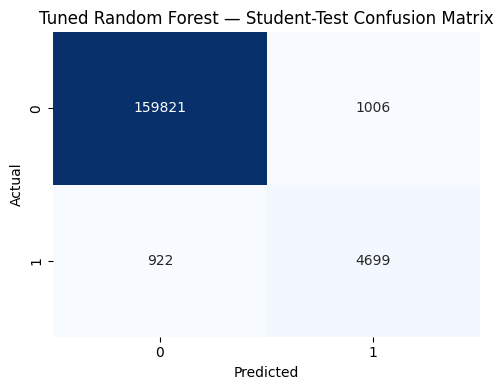

In [9]:
t0 = time.time()
student_prob = tuned_rf.predict_proba(X_student)[:,1]
student_inference_time = time.time() - t0
student_pred = (student_prob >= BEST_THRESHOLD).astype(int)

student_candidate = candidate_metrics(y_student, student_prob, BEST_THRESHOLD)
student_observation = observation_top1(student_meta, y_student, student_prob)
student_summary = {
    'Model':'Tuned Random Forest',
    'Threshold':BEST_THRESHOLD,
    **student_candidate,
    **student_observation,
    'Inference Time (s)':student_inference_time,
    'Route Continuity':'N/A - sequence decoder not evaluated in this notebook'
}
student_results = pd.DataFrame([student_summary])
display(student_results.round(4))
student_results.to_csv(RESULT_DIR/'student_test_final_metrics.csv', index=False)

print('Student-test classification report:')
print(classification_report(y_student, student_pred, zero_division=0))
cm = confusion_matrix(y_student, student_pred, labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Tuned Random Forest — Student-Test Confusion Matrix')
plt.tight_layout()
plt.savefig(RESULT_DIR/'student_test_confusion_matrix.png', dpi=180)
plt.show()

## 10. Compare all five models on student-test

In [10]:
student_rows = []
for name, model in models.items():
    t0 = time.time()
    prob = model.predict_proba(X_student)[:,1]
    elapsed = time.time()-t0
    row = {'Model':name, **candidate_metrics(y_student, prob)}
    row.update(observation_top1(student_meta, y_student, prob))
    row['Inference Time (s)'] = elapsed
    row['Route Continuity'] = 'N/A - no validated sequence decoder metric'
    student_rows.append(row)

# Tuned RF uses its validation-selected threshold for hard-label metrics.
tuned_row = {'Model':'Tuned Random Forest', **candidate_metrics(y_student, student_prob, BEST_THRESHOLD)}
tuned_row.update(student_observation)
tuned_row['Inference Time (s)'] = student_inference_time
tuned_row['Route Continuity'] = 'N/A - no validated sequence decoder metric'
student_comparison = pd.DataFrame(student_rows + [tuned_row])
display(student_comparison.round(4))
student_comparison.to_csv(RESULT_DIR/'student_test_model_comparison.csv', index=False)

# Report-ready merged table. CV Macro F1 is N/A: this notebook uses a held-out trip-wise validation split, not k-fold CV.
report_table = validation_results[['Model','Macro F1','Observation Top-1 Accuracy','Log Loss','Validation Inference Time (s)']].merge(
    student_comparison[['Model','Macro F1','Observation Top-1 Accuracy','Log Loss','Inference Time (s)','Route Continuity']],
    on='Model', how='outer', suffixes=('_Validation','_StudentTest')
)
report_table['CV Macro F1-score'] = 'N/A - group holdout used, not k-fold CV'
report_table['Route continuity'] = report_table['Route Continuity']
display(report_table)
report_table.to_csv(RESULT_DIR/'report_model_comparison_table.csv', index=False)

,Model,Candidate Accuracy,Candidate Precision,Candidate Recall,Candidate F1,Macro F1,Log Loss,ROC AUC,Average Precision,Observation Top-1 Accuracy,Observation Macro F1,Observations Evaluated,Inference Time (s),Route Continuity
0,Random Forest,0.9798,0.6367,0.9347,0.7574,0.8734,0.0631,0.9909,0.8877,0.8432,0.4575,5662,0.8085,N/A - no validated sequence decoder metric
1,Logistic Regression,0.9070,0.2627,0.9708,0.4135,0.6815,0.1827,0.9840,0.7824,0.8248,0.4520,5662,0.0198,N/A - no validated sequence decoder metric
2,Decision Tree,0.9704,0.5356,0.9342,0.6808,0.8327,0.1056,0.9637,0.8507,0.8336,0.4546,5662,0.0239,N/A - no validated sequence decoder metric
3,HistGradientBoosting,0.9653,0.4930,0.9612,0.6517,0.8167,0.0930,0.9915,0.8894,0.8458,0.4582,5662,1.2756,N/A - no validated sequence decoder metric
4,KNN,0.9847,0.7824,0.7591,0.7706,0.8813,0.0873,0.9553,0.7775,0.8082,0.4470,5662,7.1906,N/A - no validated sequence decoder metric
5,Tuned Random Forest,0.9884,0.8237,0.8360,0.8298,0.9119,0.0480,0.9903,0.8884,0.8442,0.4578,5662,1.1465,N/A - no validated sequence decoder metric


,Model,Macro F1_Validation,Observation Top-1 Accuracy_Validation,Log Loss_Validation,Validation Inference Time (s),Macro F1_StudentTest,Observation Top-1 Accuracy_StudentTest,Log Loss_StudentTest,Inference Time (s),Route Continuity,CV Macro F1-score,Route continuity
0,Decision Tree,0.839321,0.823333,0.109043,0.040879,0.832668,0.833628,0.105615,0.023926,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric
1,HistGradientBoosting,0.823886,0.827812,0.095402,2.088957,0.816726,0.845814,0.093014,1.275616,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric
2,KNN,0.872667,0.776875,0.089842,11.184431,0.881334,0.808195,0.087256,7.190633,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric
3,Logistic Regression,0.687711,0.811771,0.186312,0.035276,0.681470,0.824797,0.182661,0.019850,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric
4,Random Forest,0.876393,0.829583,0.065325,1.793498,0.873447,0.843165,0.063066,0.808475,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric
5,Tuned Random Forest,NaN,NaN,NaN,NaN,0.911888,0.844225,0.048039,1.146502,N/A - no validated sequence decoder metric,"N/A - group holdout used, not k-fold CV",N/A - no validated sequence decoder metric


## 11. Save trained models, preprocessing/configuration, and reproducibility metadata

In [11]:
# Save every experimented model plus the tuned champion.
for name, model in models.items():
    safe = name.lower().replace(' ','_')
    joblib.dump(model, MODEL_DIR/f'{safe}.joblib', compress=3)
joblib.dump(tuned_rf, MODEL_DIR/'tuned_random_forest.joblib', compress=3)

config = {
    'project':'PathSnap',
    'features':FEATURES,
    'target':TARGET,
    'split':'GroupShuffleSplit(test_size=0.20, random_state=42)',
    'initial_models':{
        'Random Forest':'100 trees, max_depth=15, min_samples_split=10, min_samples_leaf=5, max_features=sqrt, class_weight=balanced',
        'Logistic Regression':'StandardScaler + LogisticRegression(class_weight=balanced, max_iter=300, lbfgs)',
        'Decision Tree':'max_depth=15, min_samples_split=10, min_samples_leaf=5, class_weight=balanced',
        'HistGradientBoosting':'max_iter=100, max_leaf_nodes=31, learning_rate=0.1, l2_regularization=1.0, class_weight=balanced',
        'KNN':'StandardScaler + 7 neighbours, distance weights; fitted on 100,000-row sample'
    },
    'tuned_random_forest':best_params,
    'selected_threshold':BEST_THRESHOLD,
    'threshold_selection':'Maximum positive-class F1 on validation set',
    'bayesian_optimization':'Optuna TPE, 8 trials, sample-based search',
    'random_state':42,
    'python':sys.version,
    'platform':platform.platform()
}
with open(MODEL_DIR/'pathsnap_model_config.json','w') as f:
    json.dump(config,f,indent=2)

metadata = {
    'train_model_ready_rows':len(train_df),
    'student_test_model_ready_rows':len(test_df),
    'training_split_rows':len(X_train),
    'validation_rows':len(X_val),
    'training_trips':int(train_meta.trip_id.nunique()),
    'validation_trips':int(val_meta.trip_id.nunique()),
    'student_test_trips':int(student_meta.trip_id.nunique()),
    'features':FEATURES
}
with open(RESULT_DIR/'run_metadata.json','w') as f:
    json.dump(metadata,f,indent=2)

print('Saved model files to:', MODEL_DIR)
print('Saved result files to:', RESULT_DIR)

Saved model files to: /content/drive/MyDrive/PathSnap/models
Saved result files to: /content/drive/MyDrive/PathSnap/model_training_results


## 12. Export a compact experiment summary and download results

In [12]:
# Include environment and key metrics in a concise experiment log.
experiment_log = {
    'validation_comparison': validation_results.to_dict(orient='records'),
    'student_test_comparison': student_comparison.to_dict(orient='records'),
    'optuna_best_value': float(study.best_value),
    'optuna_best_params': study.best_params,
    'selected_threshold': BEST_THRESHOLD,
    'student_test_tuned_rf': student_summary,
    'caveats': [
        'Student-test refers to the supplied student_test partition, not the reserved evaluator partition.',
        'Candidate-level metrics evaluate candidate labels; observation Top-1 selects the highest-scoring candidate per observation.',
        'Route continuity is N/A because a validated HMM/Viterbi decoder was not evaluated here.',
        'CV Macro F1 is N/A because the split is trip-wise holdout, not k-fold cross-validation.',
        'Bayesian search uses a capped reproducible sample for runtime; final tuned model is refit on the full training split.'
    ]
}
with open(RESULT_DIR/'experiment_summary.json','w') as f:
    json.dump(experiment_log,f,indent=2,default=float)

# Zip outputs for one-click download / repository upload.
import shutil, zipfile
bundle_path = PROJECT_DIR/'model_training_deliverables.zip'
shutil.make_archive(str(bundle_path.with_suffix('')), 'zip',
                    root_dir=PROJECT_DIR,
                    base_dir='model_training_results')
# Add models separately to the bundle (model files can be large).
with zipfile.ZipFile(bundle_path, 'a', compression=zipfile.ZIP_DEFLATED) as zf:
    for fp in MODEL_DIR.glob('*'):
        zf.write(fp, arcname=f'models/{fp.name}')

print('Deliverables ZIP:', bundle_path)
print('Result directory contents:')
for fp in sorted(RESULT_DIR.iterdir()):
    print(fp.name, round(fp.stat().st_size/1024,1), 'KB')
from google.colab import files
files.download(str(bundle_path))

Deliverables ZIP: /content/drive/MyDrive/PathSnap/model_training_deliverables.zip
Result directory contents:
experiment_summary.json 8.5 KB
optuna_rf_best_config.json 0.4 KB
optuna_rf_trials.csv 1.1 KB
random_forest_feature_importance.csv 0.3 KB
random_forest_feature_importance.png 50.4 KB
report_model_comparison_table.csv 1.9 KB
rf_threshold_analysis.csv 0.9 KB
run_metadata.json 0.4 KB
student_test_confusion_matrix.png 30.4 KB
student_test_final_metrics.csv 0.5 KB
student_test_model_comparison.csv 1.8 KB
validation_confusion_matrices.png 93.3 KB
validation_log_loss.png 69.1 KB
validation_macro_f1.png 61.7 KB
validation_model_comparison.csv 1.4 KB
validation_observation_top1.png 76.0 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. HMM + Viterbi map matching and route reconstruction

This section applies sequence decoding to the candidate road segments. The Random Forest probability is the emission likelihood. The transition likelihood compares GPS displacement with an approximate directed road-network distance between projected positions on consecutive candidate arcs. A bounded graph search is used to avoid unbounded searches on the large road network.

**Important evaluation rule:** the supplied `student_test` partition is a development/test partition with reference-route labels. It is not the reserved evaluator partition. HMM parameters below are fixed and reported transparently; no claim is made that sequence decoding improves accuracy unless the measured results show it.

In [13]:
# HMM setup: extract only network files from the original ZIP if not already present.
import zipfile, os, math, time, json, heapq, shutil
from pathlib import Path
from collections import defaultdict, deque

DATA_ZIP = PROJECT_DIR / 'data' / 'Student folder.zip'
NETWORK_DIR = Path('/content/pathsnap_network')
NETWORK_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_ZIP.exists(), f'Cannot find original dataset ZIP: {DATA_ZIP}'

with zipfile.ZipFile(DATA_ZIP) as zf:
    network_members = [n for n in zf.namelist() if n.endswith(('.arcs', '.nodes', '.track', '.route'))]
    for member in network_members:
        out = NETWORK_DIR / member
        if not out.exists():
            out.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(member) as src, open(out, 'wb') as dst:
                shutil.copyfileobj(src, dst)

RAW_ROOT = NETWORK_DIR / 'Student folder'
assert (RAW_ROOT / 'student_test').exists(), 'Expected Student folder/student_test inside ZIP'
print('Extracted raw trip files:', len(network_members))
print('Raw dataset root:', RAW_ROOT)

Extracted raw trip files: 360
Raw dataset root: /content/pathsnap_network/Student folder


In [14]:
# HMM hyperparameters. Keep top-K small for practical Colab runtime.
HMM_TOP_K = 8
HMM_MAX_HOPS = 8
HMM_SIGMA_METRES = 100.0
HMM_TRANSITION_WEIGHT = 0.05
HMM_UNREACHABLE_LOG_PENALTY = 10.0
HMM_EPS = 1e-9

# Great-circle distance in metres.
def haversine_m(lon1, lat1, lon2, lat2):
    r = 6371000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = np.radians(lat2-lat1)
    dl = np.radians(lon2-lon1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*r*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def load_trip_graph(trip_dir):
    tid = trip_dir.name
    arcs = pd.read_csv(trip_dir/f'{tid}.arcs', sep=r'\s+', header=None,
                       names=['from_node','to_node'])
    nodes = pd.read_csv(trip_dir/f'{tid}.nodes', sep=r'\s+', header=None,
                        names=['longitude','latitude'])
    arcs['arc_id'] = np.arange(len(arcs), dtype=int)
    node_xy = nodes[['longitude','latitude']].to_numpy(float)
    u = arcs.from_node.to_numpy(int); v = arcs.to_node.to_numpy(int)
    lengths = haversine_m(node_xy[u,0], node_xy[u,1], node_xy[v,0], node_xy[v,1])
    arcs['length_m'] = lengths
    arc_from = dict(zip(arcs.arc_id, arcs.from_node))
    arc_to = dict(zip(arcs.arc_id, arcs.to_node))
    arc_len = dict(zip(arcs.arc_id, arcs.length_m))
    outgoing = defaultdict(list)
    for row in arcs.itertuples(index=False):
        outgoing[int(row.from_node)].append((int(row.arc_id), int(row.to_node), float(row.length_m)))
    return arcs, nodes, arc_from, arc_to, arc_len, outgoing

# Bounded breadth-first search. Among paths within the hop limit, the first
# discovered path is the minimum-hop directed path; length is summed over it.
def bounded_road_path(start_node, target_node, outgoing, max_hops=HMM_MAX_HOPS):
    if start_node == target_node:
        return 0.0, []
    q = deque([(int(start_node), 0.0, [])])
    visited_depth = {int(start_node): 0}
    while q:
        node, dist, path = q.popleft()
        depth = len(path)
        if depth >= max_hops:
            continue
        for aid, nxt, length in outgoing.get(node, []):
            new_path = path + [aid]
            new_dist = dist + length
            if nxt == target_node:
                return new_dist, new_path
            nd = depth + 1
            if nd < visited_depth.get(nxt, 10**9):
                visited_depth[nxt] = nd
                q.append((nxt, new_dist, new_path))
    return None, None

### 13.1 Viterbi decoder

For each observation, the highest-emission candidates form the hidden states. Emission log-probability comes from the tuned Random Forest. The transition score is a Gaussian penalty on the difference between GPS displacement and approximate road distance. If no directed path is found within the bounded search, a fixed penalty is applied rather than silently inventing a road connection.

In [17]:
def decode_trip_viterbi(trip_df, trip_dir, model=tuned_rf, top_k=HMM_TOP_K,
                        sigma=HMM_SIGMA_METRES, transition_weight=HMM_TRANSITION_WEIGHT):
    """Return observation-level Viterbi predictions and diagnostic metrics for one trip."""
    tid = trip_dir.name
    arcs, nodes, arc_from, arc_to, arc_len, outgoing = load_trip_graph(trip_dir)
    valid = trip_df[trip_df.arc_id.between(0, len(arcs)-1)].copy()
    if valid.empty:
        return None

    # Predict RF emissions for every candidate row, then retain top-K per observation.
    x = valid[FEATURES].replace([np.inf, -np.inf], np.nan)
    probs = model.predict_proba(x)[:, 1]
    valid['emission_prob'] = np.clip(probs, HMM_EPS, 1-HMM_EPS)
    groups = []
    for obs, g in valid.groupby('obs_index', sort=True):
        groups.append(g.nlargest(top_k, 'emission_prob').reset_index(drop=True))
    if not groups:
        return None

    # GPS displacement is computed from original track rows indexed by obs_index.
    track_path = trip_dir/f'{tid}.track'
    track = pd.read_csv(track_path, sep=r'\s+', header=None,
                        names=['longitude','latitude','timestamp'])
    track_xy = track[['longitude','latitude']].to_numpy(float)
    obs_ids = [int(g.obs_index.iloc[0]) for g in groups]
    gps_step = [0.0]
    for i in range(1, len(obs_ids)):
        a, b = obs_ids[i-1], obs_ids[i]
        if a < len(track_xy) and b < len(track_xy):
            d = haversine_m(track_xy[a,0], track_xy[a,1], track_xy[b,0], track_xy[b,1])
        else:
            d = 0.0
        gps_step.append(float(d))

    # Multi-target bounded BFS: one graph traversal per previous candidate and
    # observation pair, rather than a separate traversal for every candidate pair.
    def bounded_paths_to_targets(start_node, target_nodes, outgoing, max_hops=HMM_MAX_HOPS):
        targets = set(int(x) for x in target_nodes)
        found = {}
        if int(start_node) in targets:
            found[int(start_node)] = (0.0, [])
            targets.remove(int(start_node))
        q = deque([(int(start_node), 0.0, [])])
        visited_depth = {int(start_node): 0}
        while q and targets:
            node, dist, path = q.popleft()
            depth = len(path)
            if depth >= max_hops:
                continue
            for aid, nxt, length in outgoing.get(node, []):
                new_path = path + [aid]
                new_dist = dist + length
                if nxt in targets:
                    found[nxt] = (new_dist, new_path)
                    targets.remove(nxt)
                    if not targets:
                        break
                nd = depth + 1
                if nd < visited_depth.get(nxt, 10**9):
                    visited_depth[nxt] = nd
                    q.append((nxt, new_dist, new_path))
        return found

    def transition(prev_row, curr_row, gps_distance, path_lookup):
        pa, ca = int(prev_row.arc_id), int(curr_row.arc_id)
        if pa == ca:
            network_mid, middle = 0.0, []
        else:
            target = int(arc_from[ca])
            result = path_lookup.get(target)
            if result is None:
                return -HMM_UNREACHABLE_LOG_PENALTY, None, None
            network_mid, middle = result
        # Distance from previous projected point to its arc end + network path
        # + distance from next arc start to its projected point.
        prev_remaining = max(0.0, (1.0-float(prev_row.projection_ratio))*float(prev_row.segment_length))
        curr_prefix = max(0.0, float(curr_row.projection_ratio)*float(curr_row.segment_length))
        road_dist = prev_remaining + float(network_mid) + curr_prefix
        scale = max(float(sigma), 0.35*float(gps_distance) + 25.0)
        logp = -0.5*((road_dist-float(gps_distance))/scale)**2
        return float(logp), float(road_dist), middle

    # Viterbi dynamic programming.
    score_history = [np.log(groups[0].emission_prob.to_numpy(float))]
    backpointers = [None]
    transition_paths = [None]
    for t in range(1, len(groups)):
        prev_g, curr_g = groups[t-1], groups[t]
        prev_scores = score_history[-1]
        curr_em = np.log(curr_g.emission_prob.to_numpy(float))
        scores = np.full(len(curr_g), -np.inf)
        ptrs = np.zeros(len(curr_g), dtype=int)
        paths_for_curr = [None] * len(curr_g)
        target_nodes = [int(arc_from[int(a)]) for a in curr_g.arc_id]
        paths_by_previous = {}
        for i, (_, prow) in enumerate(prev_g.iterrows()):
            source_node = int(arc_to[int(prow.arc_id)])
            paths_by_previous[i] = bounded_paths_to_targets(
                source_node, target_nodes, outgoing, HMM_MAX_HOPS
            )
        for j, (_, crow) in enumerate(curr_g.iterrows()):
            best_score, best_i, best_path = -np.inf, 0, None
            for i, (_, prow) in enumerate(prev_g.iterrows()):
                trans_logp, road_dist, middle = transition(
                    prow, crow, gps_step[t], paths_by_previous[i]
                )
                candidate_score = prev_scores[i] + curr_em[j] + transition_weight*trans_logp
                if candidate_score > best_score:
                    best_score, best_i, best_path = candidate_score, i, middle
            scores[j], ptrs[j], paths_for_curr[j] = best_score, best_i, best_path
        score_history.append(scores)
        backpointers.append(ptrs)
        transition_paths.append(paths_for_curr)

    state = int(np.argmax(score_history[-1]))
    chosen = [state]
    for t in range(len(groups)-1, 0, -1):
        state = int(backpointers[t][state])
        chosen.append(state)
    chosen.reverse()

    records = []
    for t, (g, state_idx) in enumerate(zip(groups, chosen)):
        row = g.iloc[state_idx]
        truth_rows = g[g.label == 1]
        true_arc = int(truth_rows.arc_id.iloc[0]) if len(truth_rows) else None
        records.append({
            'trip_id': tid, 'obs_index': int(row.obs_index),
            'predicted_arc': int(row.arc_id), 'true_arc': true_arc,
            'emission_prob': float(row.emission_prob),
            'correct': (int(row.arc_id) == true_arc) if true_arc is not None else np.nan,
            'projection_ratio': float(row.projection_ratio),
            'segment_length': float(row.segment_length)
        })
    pred_df = pd.DataFrame(records)

    # Route continuity is the share of adjacent decoded arc pairs that are
    # directly connected or connected by a bounded directed path.
    connected = []
    expanded_route = []
    for t in range(1, len(groups)):
        prev_arc = int(groups[t-1].iloc[chosen[t-1]].arc_id)
        curr_arc = int(groups[t].iloc[chosen[t]].arc_id)
        if t == 1:
            expanded_route.append(prev_arc)
        if prev_arc == curr_arc:
            connected.append(True)
            continue
        mid, path = bounded_road_path(arc_to[prev_arc], arc_from[curr_arc], outgoing, HMM_MAX_HOPS)
        ok = path is not None
        connected.append(ok)
        if ok:
            expanded_route.extend(path)
        expanded_route.append(curr_arc)
    pred_df.attrs['route_continuity'] = float(np.mean(connected)) if connected else np.nan
    pred_df.attrs['expanded_route_arc_ids'] = expanded_route
    pred_df.attrs['transition_reachability'] = float(np.mean(connected)) if connected else np.nan
    pred_df.attrs['network_arcs'] = arcs
    pred_df.attrs['network_nodes'] = nodes
    pred_df.attrs['track'] = track
    return pred_df

### 13.2 Run Viterbi on every supplied student-test trip

This is the held-out supplied `student_test` partition. The notebook reports observation-level arc accuracy, candidate recall coverage, route continuity, and runtime per trip. A missing true arc in the candidate set cannot be recovered by Viterbi, so candidate recall remains an upper bound.

In [18]:
hmm_rows = []
hmm_predictions = {}
hmm_route_ids = {}
hmm_runtime_rows = []

student_root = RAW_ROOT / 'student_test'
for trip_dir in sorted(p for p in student_root.iterdir() if p.is_dir()):
    tid = trip_dir.name
    trip_candidates = test_df[pd.to_numeric(test_df.trip_id, errors='coerce').astype('Int64').astype(str).str.zfill(8) == tid].copy()
    if trip_candidates.empty:
        continue
    t0 = time.time()
    decoded = decode_trip_viterbi(trip_candidates, trip_dir)
    elapsed = time.time() - t0
    if decoded is None:
        continue
    hmm_predictions[tid] = decoded
    hmm_route_ids[tid] = decoded.attrs.get('expanded_route_arc_ids', [])
    labelled = decoded.dropna(subset=['true_arc'])
    hmm_rows.append({
        'trip_id': tid,
        'observations_decoded': len(decoded),
        'labelled_observations': len(labelled),
        'Viterbi Top-1 Accuracy': float(labelled.correct.mean()) if len(labelled) else np.nan,
        'Route Continuity': decoded.attrs.get('route_continuity', np.nan),
        'Transition Reachability': decoded.attrs.get('transition_reachability', np.nan),
        'Inference Time (s)': elapsed
    })
    print(f'{tid}: {len(decoded)} observations | accuracy={hmm_rows[-1]["Viterbi Top-1 Accuracy"]:.4f} | continuity={hmm_rows[-1]["Route Continuity"]:.4f} | {elapsed:.1f}s')

hmm_student_results = pd.DataFrame(hmm_rows)
assert len(hmm_student_results), 'No student-test trips were decoded. Check trip IDs and raw dataset paths.'
display(hmm_student_results.round(4))
hmm_student_results.to_csv(RESULT_DIR/'hmm_viterbi_student_test_by_trip.csv', index=False)

# Aggregate observation-weighted accuracy and transition-weighted route continuity.
all_hmm_obs = pd.concat(hmm_predictions.values(), ignore_index=True)
labelled_all_hmm = all_hmm_obs.dropna(subset=['true_arc'])
hmm_aggregate = {
    'Model': 'Tuned RF + HMM/Viterbi',
    'Student-Test Viterbi Top-1 Accuracy': float(labelled_all_hmm.correct.mean()),
    'Student-Test Observations': int(len(labelled_all_hmm)),
    'Mean Trip Route Continuity': float(hmm_student_results['Route Continuity'].mean()),
    'Mean Trip Inference Time (s)': float(hmm_student_results['Inference Time (s)'].mean()),
    'Trips Decoded': int(len(hmm_student_results)),
    'Top-K States': HMM_TOP_K,
    'Max Search Hops': HMM_MAX_HOPS,
    'Sigma (m)': HMM_SIGMA_METRES,
    'Transition Weight': HMM_TRANSITION_WEIGHT
}
print('\nAGGREGATE HMM/VITERBI STUDENT-TEST RESULTS')
print(json.dumps(hmm_aggregate, indent=2))
with open(RESULT_DIR/'hmm_viterbi_summary.json','w') as f:
    json.dump(hmm_aggregate, f, indent=2)

00000000: 600 observations | accuracy=0.8134 | continuity=0.9349 | 5.5s
00000007: 600 observations | accuracy=0.9217 | continuity=0.9967 | 4.8s
00000009: 600 observations | accuracy=0.8928 | continuity=0.9983 | 6.6s
00000040: 600 observations | accuracy=0.9032 | continuity=0.9549 | 5.0s
00000052: 262 observations | accuracy=0.9695 | continuity=0.9923 | 2.0s
00000056: 600 observations | accuracy=0.7723 | continuity=0.9616 | 6.1s
00000065: 600 observations | accuracy=0.7930 | continuity=0.9716 | 4.8s
00000076: 600 observations | accuracy=0.8712 | continuity=0.9900 | 5.2s
00000077: 600 observations | accuracy=0.7527 | continuity=1.0000 | 6.4s
00000091: 600 observations | accuracy=0.8367 | continuity=0.9766 | 4.9s


,trip_id,observations_decoded,labelled_observations,Viterbi Top-1 Accuracy,Route Continuity,Transition Reachability,Inference Time (s)
0,00000000,600,595,0.8134,0.9349,0.9349,5.5084
1,00000007,600,600,0.9217,0.9967,0.9967,4.8026
2,00000009,600,569,0.8928,0.9983,0.9983,6.6240
3,00000040,600,599,0.9032,0.9549,0.9549,5.0450
4,00000052,262,262,0.9695,0.9923,0.9923,2.0296
5,00000056,600,584,0.7723,0.9616,0.9616,6.1010
6,00000065,600,575,0.7930,0.9716,0.9716,4.7878
7,00000076,600,598,0.8712,0.9900,0.9900,5.1524
8,00000077,600,558,0.7527,1.0000,1.0000,6.4333
9,00000091,600,600,0.8367,0.9766,0.9766,4.8983



AGGREGATE HMM/VITERBI STUDENT-TEST RESULTS
{
  "Model": "Tuned RF + HMM/Viterbi",
  "Student-Test Viterbi Top-1 Accuracy": 0.8465703971119134,
  "Student-Test Observations": 5540,
  "Mean Trip Route Continuity": 0.977697823319837,
  "Mean Trip Inference Time (s)": 5.138241767883301,
  "Trips Decoded": 10,
  "Top-K States": 8,
  "Max Search Hops": 8,
  "Sigma (m)": 100.0,
  "Transition Weight": 0.05
}


### 13.3 Compare RF observation Top-1 against Viterbi

The baseline is the same tuned Random Forest emission model selecting the highest-probability candidate independently at each observation. Both methods are evaluated on the same decoded observations.

In [19]:
baseline_rows = []
for tid, decoded in hmm_predictions.items():
    trip_candidates = test_df[pd.to_numeric(test_df.trip_id, errors='coerce').astype('Int64').astype(str).str.zfill(8) == tid].copy()
    xx = trip_candidates[FEATURES].replace([np.inf,-np.inf], np.nan)
    trip_candidates['rf_prob'] = tuned_rf.predict_proba(xx)[:,1]
    top = trip_candidates.sort_values(['obs_index','rf_prob'], ascending=[True,False]).groupby('obs_index').first().reset_index()
    truth = decoded[['obs_index','true_arc']].drop_duplicates()
    joined = top[['obs_index','arc_id']].merge(truth, on='obs_index', how='inner')
    joined = joined.dropna(subset=['true_arc'])
    baseline_rows.append({'trip_id':tid, 'RF Top-1 Accuracy':float((joined.arc_id.to_numpy()==joined.true_arc.to_numpy()).mean()),
                          'Viterbi Top-1 Accuracy':float(decoded.dropna(subset=['true_arc']).correct.mean())})
baseline_vs_hmm = pd.DataFrame(baseline_rows)
display(baseline_vs_hmm.round(4))
baseline_vs_hmm.to_csv(RESULT_DIR/'rf_vs_viterbi_student_test.csv', index=False)
print('RF aggregate accuracy:', baseline_vs_hmm['RF Top-1 Accuracy'].mean())
print('Viterbi aggregate accuracy:', baseline_vs_hmm['Viterbi Top-1 Accuracy'].mean())

,trip_id,RF Top-1 Accuracy,Viterbi Top-1 Accuracy
0,00000000,0.9445,0.8134
1,00000007,0.9233,0.9217
2,00000009,0.8858,0.8928
3,00000040,0.9416,0.9032
4,00000052,0.9580,0.9695
5,00000056,0.7740,0.7723
6,00000065,0.8035,0.7930
7,00000076,0.8796,0.8712
8,00000077,0.7491,0.7527
9,00000091,0.8117,0.8367


RF aggregate accuracy: 0.8671040332028763
Viterbi aggregate accuracy: 0.8526440072163863


### 13.4 Folium map: GPS observations, RF candidates and reconstructed Viterbi route

The map is generated for the first student-test trip that has a decoded route. It overlays observed GPS points, the Viterbi-selected road arcs, and the reference route from the supplied `.route` file when available. This is a visual diagnostic, not a substitute for the quantitative metrics.

In [20]:
%pip -q install folium
import folium

MAP_DIR = RESULT_DIR/'maps'
MAP_DIR.mkdir(exist_ok=True)
map_tid = next(iter(hmm_predictions))
map_trip_dir = student_root/map_tid
map_decoded = hmm_predictions[map_tid]
map_arcs, map_nodes, map_from, map_to, map_len, map_out = load_trip_graph(map_trip_dir)
map_track = map_decoded.attrs['track'] if 'track' in map_decoded.attrs else pd.read_csv(map_trip_dir/f'{map_tid}.track', sep=r'\s+', header=None, names=['longitude','latitude','timestamp'])
center = [float(map_track.latitude.median()), float(map_track.longitude.median())]
fmap = folium.Map(location=center, zoom_start=14, tiles='CartoDB positron')

# GPS observations.
for _, r in map_track.iloc[::max(1, len(map_track)//300)].iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=2, color='#2563eb', fill=True,
                        fill_opacity=0.65, tooltip='GPS observation').add_to(fmap)

# Draw decoded arc sequence (expanded with bounded connecting arcs where found).
route_ids = list(dict.fromkeys(map_decoded.attrs.get('expanded_route_arc_ids', [])))
route_coords = []
for aid in route_ids:
    if aid < 0 or aid >= len(map_arcs):
        continue
    u = int(map_arcs.iloc[aid].from_node); v = int(map_arcs.iloc[aid].to_node)
    route_coords.append([float(map_nodes.iloc[u].latitude), float(map_nodes.iloc[u].longitude)])
    route_coords.append([float(map_nodes.iloc[v].latitude), float(map_nodes.iloc[v].longitude)])
if route_coords:
    folium.PolyLine(route_coords, color='#dc2626', weight=4, opacity=0.85,
                    tooltip='HMM/Viterbi reconstructed route').add_to(fmap)

# Ground-truth route from .route if supplied.
route_file = map_trip_dir/f'{map_tid}.route'
if route_file.exists():
    try:
        ref_ids = pd.read_csv(route_file, sep=r'\s+', header=None).iloc[:,0].astype(int).tolist()
        ref_coords=[]
        for aid in ref_ids:
            if 0 <= aid < len(map_arcs):
                u=int(map_arcs.iloc[aid].from_node); v=int(map_arcs.iloc[aid].to_node)
                if not ref_coords:
                    ref_coords.append([float(map_nodes.iloc[u].latitude), float(map_nodes.iloc[u].longitude)])
                ref_coords.append([float(map_nodes.iloc[v].latitude), float(map_nodes.iloc[v].longitude)])
        if ref_coords:
            folium.PolyLine(ref_coords, color='#16a34a', weight=3, opacity=0.7,
                            tooltip='Reference route').add_to(fmap)
    except Exception as e:
        print('Reference route could not be drawn:', e)

folium.LayerControl().add_to(fmap)
map_path = MAP_DIR/f'hmm_viterbi_trip_{map_tid}.html'
fmap.save(str(map_path))
print('Saved Folium map:', map_path)
display(fmap)

Saved Folium map: /content/drive/MyDrive/PathSnap/model_training_results/maps/hmm_viterbi_trip_00000000.html


### 13.5 Save HMM/Viterbi artifacts and report-ready metrics

In [21]:
# Save observation-level predictions for reproducibility.
hmm_obs_export = pd.concat([df.assign(trip_id=tid) for tid,df in hmm_predictions.items()], ignore_index=True)
hmm_obs_export.to_csv(RESULT_DIR/'hmm_viterbi_student_test_predictions.csv', index=False)

hmm_config = {
    'emission_model': 'Tuned Random Forest',
    'emission_probability': 'predict_proba positive-class probability',
    'decoder': 'Viterbi dynamic programming',
    'top_k_candidates_per_observation': HMM_TOP_K,
    'transition_distance': 'previous projected point to previous arc end + bounded directed shortest-hop path + current arc start to current projected point',
    'max_intermediate_hops': HMM_MAX_HOPS,
    'transition_likelihood': 'Gaussian log score on absolute difference between road distance and GPS displacement',
    'sigma_metres': HMM_SIGMA_METRES,
    'transition_weight': HMM_TRANSITION_WEIGHT,
    'unreachable_transition_penalty': HMM_UNREACHABLE_LOG_PENALTY,
    'student_test_metrics': hmm_aggregate,
    'limitations': [
        'Bounded BFS finds a minimum-hop directed path within the hop limit, not a globally shortest weighted path.',
        'If no path is found within the hop limit, a fixed transition penalty is used.',
        'Student-test is the supplied development partition, not the reserved evaluator set.',
        'Viterbi cannot recover the reference arc when candidate generation omitted it.'
    ]
}
with open(MODEL_DIR/'pathsnap_hmm_viterbi_config.json','w') as f:
    json.dump(hmm_config, f, indent=2, default=float)

# Compact report table: candidate classifier metrics plus sequence-decoder route metrics.
hmm_report_table = pd.DataFrame([{
    'Pipeline': 'Tuned Random Forest + HMM/Viterbi',
    'Student-Test Viterbi Top-1 Accuracy': hmm_aggregate['Student-Test Viterbi Top-1 Accuracy'],
    'Mean Trip Route Continuity': hmm_aggregate['Mean Trip Route Continuity'],
    'Trips Decoded': hmm_aggregate['Trips Decoded'],
    'Mean Trip Inference Time (s)': hmm_aggregate['Mean Trip Inference Time (s)']
}])
hmm_report_table.to_csv(RESULT_DIR/'report_hmm_viterbi_metrics.csv', index=False)
print('Saved HMM config, predictions, per-trip metrics and report table.')

Saved HMM config, predictions, per-trip metrics and report table.


## 14. Final consolidated export

This final cell rebuilds the ZIP after the HMM section has run, so the bundle includes classifier models, tuned configuration, candidate-level results, HMM/Viterbi predictions, route metrics, maps and experiment logs.

In [22]:
# Rebuild a complete archive containing outputs, models and HMM maps.
FINAL_BUNDLE = PROJECT_DIR/'PathSnap_complete_model_training_and_hmm_deliverables.zip'
if FINAL_BUNDLE.exists():
    FINAL_BUNDLE.unlink()
with zipfile.ZipFile(FINAL_BUNDLE, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for base, arcname in [(RESULT_DIR, 'model_training_results'), (MODEL_DIR, 'models')]:
        for fp in base.rglob('*'):
            if fp.is_file():
                zf.write(fp, arcname=str(Path(arcname)/fp.relative_to(base)))
print('Complete deliverables bundle:', FINAL_BUNDLE)
print('Bundle size (MB):', round(FINAL_BUNDLE.stat().st_size/1024/1024, 2))
from google.colab import files
files.download(str(FINAL_BUNDLE))

Complete deliverables bundle: /content/drive/MyDrive/PathSnap/PathSnap_complete_model_training_and_hmm_deliverables.zip
Bundle size (MB): 53.57


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>